In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                              roc_curve, roc_auc_score, precision_recall_curve, RocCurveDisplay)
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", context="notebook")
UP_BLUE, UP_RED, UP_GOLD = "#003366", "#BA0C2F", "#C69214"

# EDA


In [61]:
df = pd.read_csv("./data_20230430.csv")
df.columns = ["character_chosen", "least_favorite", "favorite_item", 
              "least_favorite_item", "favorite_track", 
              "least_favorite_track", "prefer_to_play_alone",
              "worried_of_red_shells", "love_Mario_Kart_parties",
              "get_road_rage", "have_time_to_play", "mix_courses",
              "competitive","tatical", "best_driver", "celebrate_loudly",
              "team_matches","love_the_music", "people_target_me",
              "simpathy_for_spiny_shells", "upset_if_I_loose", 
              "just_happy_to_be_involved", "welcoming_person_to_play",
              "only_play_with_favorite_character", "involve_everyone",
              "cheer_others_if_winning", "cheat"
              ]


In [62]:
print(df.shape)
df.head()

(2714, 27)


,character_chosen,least_favorite,favorite_item,least_favorite_item,favorite_track,least_favorite_track,prefer_to_play_alone,worried_of_red_shells,love_Mario_Kart_parties,get_road_rage,...,love_the_music,people_target_me,simpathy_for_spiny_shells,upset_if_I_loose,just_happy_to_be_involved,welcoming_person_to_play,only_play_with_favorite_character,involve_everyone,cheer_others_if_winning,cheat
0,Bowser,Lakitu,Red Shell,Bomerang Flower,Mario Kart Stadium,N64 Rainbow Road,1,4,5,5,...,3,5,4,4,2,5,1,3,4,1
1,Yoshi,Bowser,Bullet Bill,Banana,Sweet Sweet Canyon,Rainbow Road,1,2,5,4,...,4,4,2,4,2,2,1,4,2,1
2,Toad,Donkey Kong,Red Shell,Banana,Shy Guy Falls,Sunshine Airport,1,2,5,4,...,3,1,2,2,4,5,1,4,5,2
3,Bowser,Inkling Girl,Green Shell,Spiny Shell,Mount Wario,Dolphin Shoals,1,2,5,1,...,4,4,5,1,3,4,5,4,4,1
4,Toad,Koopa Trooper,Lightning,Bomb-omb,Rainbow Road,Bowser's Castle,1,3,5,5,...,4,2,1,3,4,4,2,3,4,1


In [63]:
df = df.drop_duplicates()
print(df.shape)

(2714, 27)


In [64]:
print(df["character_chosen"].value_counts())

character_chosen
Yoshi              224
Tanooki Mario      222
Toad               212
Peach              191
Daisy              179
Luigi              160
Mario              158
Rosalina           150
King Boo           145
Donkey Kong        145
Link               142
Bowser             104
Waluigi             88
Morton              88
Dry Bowser          87
Wario               81
Metal Mario         77
Shy Guy             45
Baby Peach          42
Koopa Troopa        39
Dry Bones           35
Isabelle            35
Baby Mario          24
Pink Gold Peach     11
Cat Peach            6
Iggy                 6
Birdo                5
Roy                  4
Ludwig               4
Baby Luigi           3
Bowser Jr.           2
Name: count, dtype: int64


In [65]:
print(df["character_chosen"].unique())
print(df["least_favorite"].unique())
print(df["favorite_item"].unique())
print(df["least_favorite_item"].unique())
print(df["favorite_track"].unique())
print(df["least_favorite_track"].unique())


['Bowser' 'Yoshi' 'Toad' 'Waluigi' 'Peach' 'Luigi' 'Daisy' 'Isabelle'
 'King Boo' 'Donkey Kong' 'Dry Bones' 'Cat Peach' 'Mario' 'Koopa Troopa'
 'Tanooki Mario' 'Dry Bowser' 'Shy Guy' 'Rosalina' 'Pink Gold Peach' 'Roy'
 'Link' 'Baby Luigi' 'Birdo' 'Ludwig' 'Iggy' 'Wario' 'Bowser Jr.' 'Morton'
 'Metal Mario' 'Baby Peach' 'Baby Mario']
['Lakitu' 'Bowser' 'Donkey Kong' 'Inkling Girl' 'Koopa Trooper'
 'Metal Mario' 'Waluigi' 'Baby Peach' 'Peach' 'Daisy' 'Wario'
 'Inkling Boy' 'Villager Female' 'Yoshi' 'Luigi' 'Mario' 'Baby Luigi'
 'Link' 'Mii' 'Dry Bones' 'Baby Mario' 'Iggy' 'Pink Gold Peach' 'Wendy'
 'Baby Rosalina' 'Morton' 'Toad' 'Villager Male' 'Shy Guy' 'King Boo'
 'Rosalina' 'Birdo' 'Larry' 'Lemmy' 'Dry Bowser' 'Ludwig' ' Villager Male'
 ' Pink Gold Peach' ' Wendy' ' Baby Luigi' ' Dry Bowser' ' Baby Rosalina'
 ' Baby Peach' ' Metal Mario' ' Yoshi' ' Mii' ' Larry' ' Iggy' ' Link'
 ' King Boo' ' Morton' ' Baby Mario' ' Inkling Girl' ' Lemmy'
 ' Koopa Trooper' ' Daisy' ' Birdo' ' Wario' 

In [66]:
numerical_features = ["prefer_to_play_alone",
              "worried_of_red_shells", "love_Mario_Kart_parties",
              "get_road_rage", "have_time_to_play", "mix_courses",
              "competitive","tatical", "best_driver", "celebrate_loudly",
              "team_matches","love_the_music", "people_target_me",
              "simpathy_for_spiny_shells", "upset_if_I_loose", 
              "just_happy_to_be_involved", "welcoming_person_to_play",
              "only_play_with_favorite_character", "involve_everyone",
              "cheer_others_if_winning", "cheat"
              ]

categorical_features = [ "least_favorite",
                        "favorite_item", "least_favorite_item",
                        "favorite_track", "least_favorite_track"]

df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True, dtype=int)


In [67]:

print(df_encoded.shape)

(2714, 180)


In [68]:
df_encoded.head()

,character_chosen,prefer_to_play_alone,worried_of_red_shells,love_Mario_Kart_parties,get_road_rage,have_time_to_play,mix_courses,competitive,tatical,best_driver,...,least_favorite_track_SNES Donut Plains 3,least_favorite_track_Shy Guy Falls,least_favorite_track_Sunshine Airport,least_favorite_track_Sweet Sweet Canyon,least_favorite_track_Thwomp Ruins,least_favorite_track_Toad Harbour,least_favorite_track_Twisted Mansion,least_favorite_track_Water Park,least_favorite_track_Wii Grumble Volcano,least_favorite_track_Wii Moo Moo Meadows
0,Bowser,1,4,5,5,4,5,5,5,4,...,0,0,0,0,0,0,0,0,0,0
1,Yoshi,1,2,5,4,5,4,5,4,2,...,0,0,0,0,0,0,0,0,0,0
2,Toad,1,2,5,4,2,5,5,5,4,...,0,0,1,0,0,0,0,0,0,0
3,Bowser,1,2,5,1,2,5,2,4,4,...,0,0,0,0,0,0,0,0,0,0
4,Toad,1,3,5,5,2,5,5,4,2,...,0,0,0,0,0,0,0,0,0,0


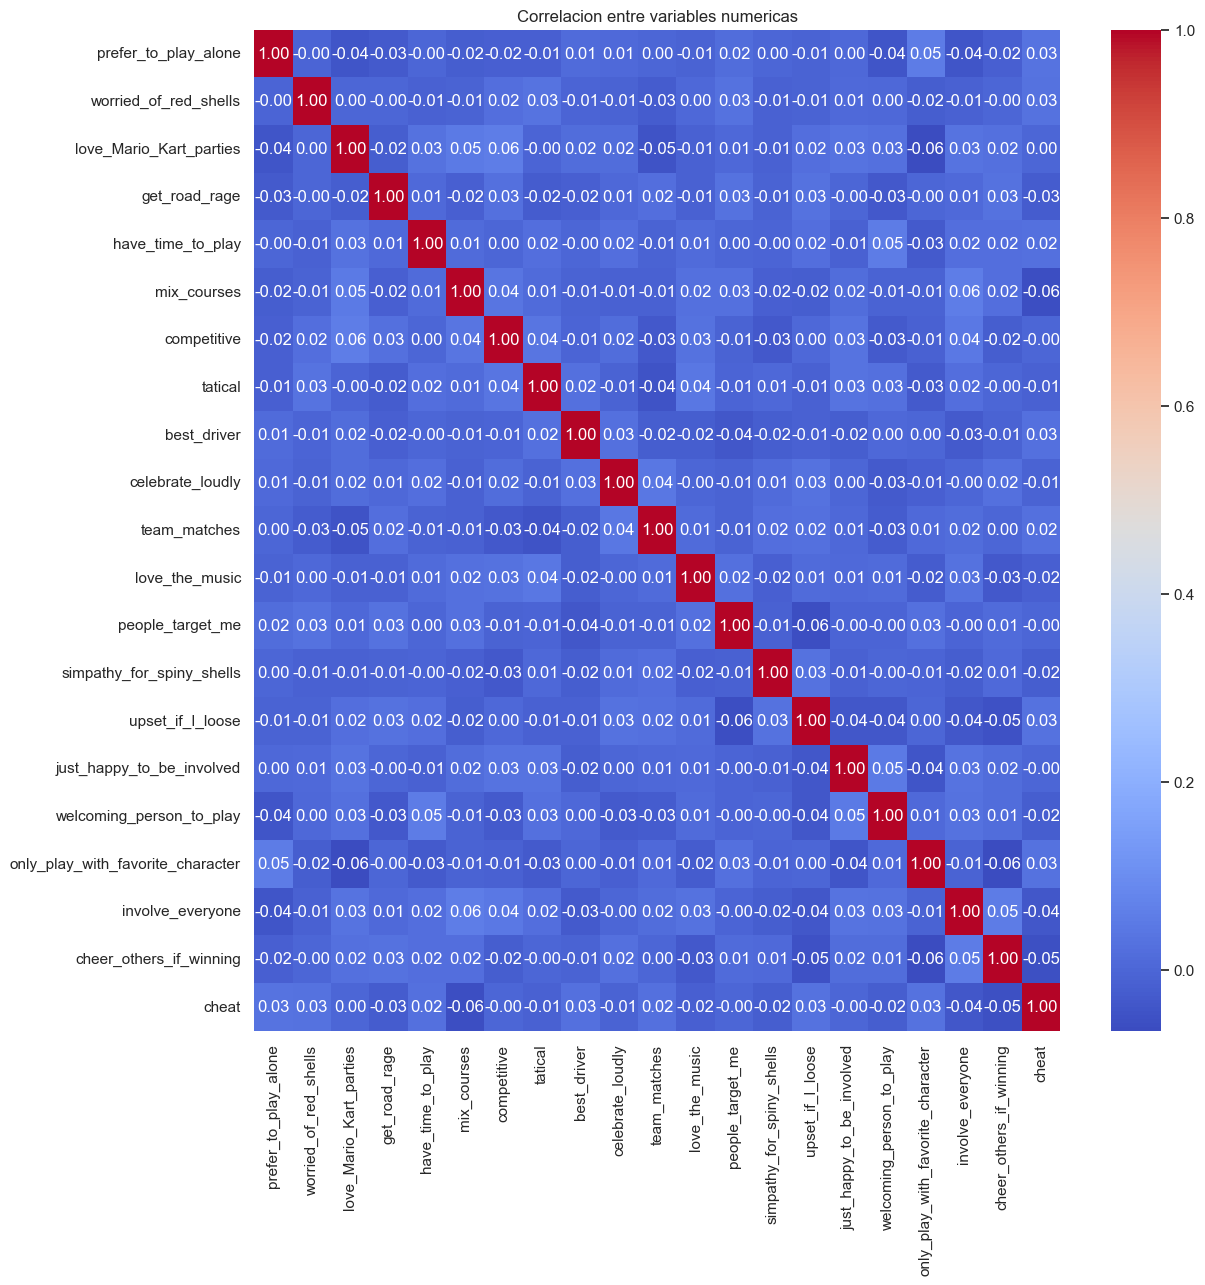

In [69]:
plt.figure(figsize=(13, 13))
sns.heatmap(df[numerical_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlacion entre variables numericas")
plt.show()

# MATRIZ DE DISEÑO

In [70]:
X = df_encoded.drop(columns=["character_chosen"])
y = df_encoded["character_chosen"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# KNN

/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/opt/miniconda3/lib/

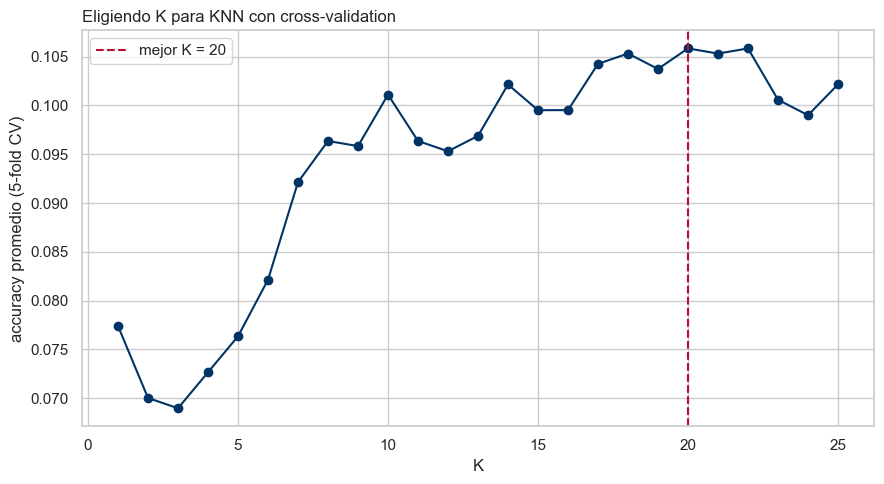

In [71]:
k_grid = range(1, 26)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in k_grid]
best_k = list(k_grid)[int(np.argmax(cv_scores))]

plt.figure(figsize=(9, 5))
plt.plot(list(k_grid), cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_k, color=UP_RED, ls="--", label=f"mejor K = {best_k}")
plt.xlabel("K")
plt.ylabel("accuracy promedio (5-fold CV)")
plt.title("Eligiendo K para KNN con cross-validation", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [72]:
KNN_model = KNeighborsClassifier(n_neighbors=best_k)
KNN_model.fit(X_train, y_train)
y_pred_knn = KNN_model.predict(X_test)

In [73]:
print(accuracy_score(y_test, y_pred_knn))

0.09938650306748466


# Árbol

In [74]:
arbol_completo = DecisionTreeClassifier(random_state=42)
path = arbol_completo.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas = path.ccp_alphas[:-1]

cv_scores = []
for alpha in ccp_alphas:
    tree = DecisionTreeClassifier(random_state=42, ccp_alpha=alpha)
    scores = cross_val_score(tree, X_train, y_train, cv=3, scoring="accuracy")
    cv_scores.append(scores.mean())

best_alpha = ccp_alphas[int(np.argmax(cv_scores))]
print(f"Mejor alpha por CV: {best_alpha:.4f}")

model_dt_pruned = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
model_dt_pruned.fit(X_train, y_train)

y_pred_dt = model_dt_pruned.predict(X_test)

print("\nAccuracy:", round(accuracy_score(y_test, y_pred_dt), 4))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred_dt, zero_division=0))

/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(
/opt/miniconda3/lib/

Mejor alpha por CV: 0.0018

Accuracy: 0.1018

Reporte de Clasificación:
                  precision    recall  f1-score   support

     Baby Luigi       0.00      0.00      0.00         1
     Baby Mario       0.00      0.00      0.00         7
     Baby Peach       0.00      0.00      0.00        13
          Birdo       0.00      0.00      0.00         1
         Bowser       0.11      0.42      0.18        31
     Bowser Jr.       0.00      0.00      0.00         1
      Cat Peach       0.00      0.00      0.00         2
          Daisy       0.08      0.28      0.13        54
    Donkey Kong       0.00      0.00      0.00        44
      Dry Bones       0.00      0.00      0.00        11
     Dry Bowser       0.00      0.00      0.00        26
           Iggy       0.00      0.00      0.00         2
       Isabelle       0.00      0.00      0.00        10
       King Boo       0.06      0.11      0.08        44
   Koopa Troopa       0.00      0.00      0.00        12
           Lin

/opt/miniconda3/lib/python3.13/site-packages/sklearn/model_selection/_split.py:813: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=3.
  warnings.warn(


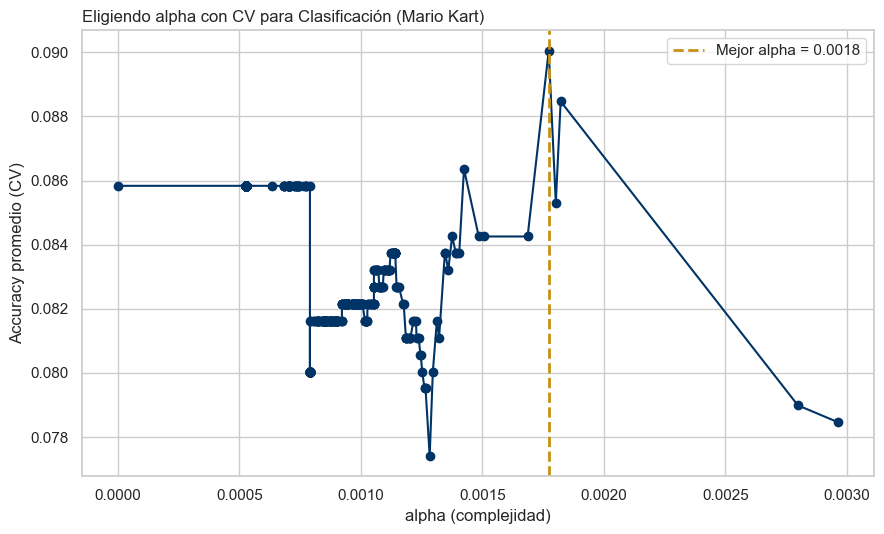

In [75]:
plt.figure(figsize=(9, 5.5))
plt.plot(ccp_alphas, cv_scores, marker="o", color=UP_BLUE)
plt.axvline(best_alpha, color=UP_GOLD, ls="--", lw=2, label=f"Mejor alpha = {best_alpha:.4f}")
plt.xlabel("alpha (complejidad)")
plt.ylabel("Accuracy promedio (CV)")
plt.title("Eligiendo alpha con CV para Clasificación (Mario Kart)", loc="left")
plt.legend()
plt.tight_layout()
plt.show()

In [76]:
arbol_podado = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha).fit(X_train, y_train)
arbol_sin_podar = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

comparacion = pd.DataFrame({
    "modelo": ["Sin podar", "Podado (CV)"],
    "n_hojas": [arbol_sin_podar.get_n_leaves(), arbol_podado.get_n_leaves()],
    "accuracy_test": [
        accuracy_score(y_test, arbol_sin_podar.predict(X_test)),
        accuracy_score(y_test, arbol_podado.predict(X_test)),
    ],
}).round(3)
comparacion

,modelo,n_hojas,accuracy_test
0,Sin podar,1139,0.083
1,Podado (CV),9,0.102


# Observaciones

Pocos datos para muchas clases, no se puede entrenar bien el modelo y por eso nos arroja un accuracy muy bajo. Tampoco se pueden podar los árboles, ya que al intentar simplificar el arbol, solo logra que el accuracy del test baje.